# ¿Influye la financiación recibida en la supervivencia y el éxito de las startups?
### Un análisis exploratorio de datos (EDA) con Python

**Proyecto del módulo Data Analysis**

---

**Índice**

1. Introducción y contexto
2. Hipótesis de partida
3. Fuentes de datos
4. Carga y primer vistazo
5. Limpieza de datos
6. Creación de variables (feature engineering)
7. Análisis univariante
8. Un sesgo importante: la edad de la startup
9. H1 y H2 — Financiación total vs. supervivencia y éxito
10. H3 — Número de rondas
11. H4 — ¿Más dinero siempre es mejor? (rendimientos decrecientes)
12. H5 — País y sector
13. Matriz de correlación
14. Resumen de hipótesis
15. Conclusiones, limitaciones y próximos pasos

## 1. Introducción y contexto

Se suele decir que **9 de cada 10 startups fracasan**. Al mismo tiempo, cada año se invierten
cientos de miles de millones de dólares en capital riesgo con la esperanza de encontrar
"el próximo unicornio". Una pregunta natural, tanto para un emprendedor como para un inversor, es:

> **¿El dinero recibido marca la diferencia entre sobrevivir y cerrar, o entre ser vendida/salir a bolsa y quedarse por el camino?**

En este proyecto analizo más de **66.000 startups** y **114.000 rondas de financiación** del
registro público de Crunchbase para responder a esa pregunta con datos.

**Definiciones clave que usaré en todo el análisis:**

| Término | Significado |
|---|---|
| **Supervivencia** | La startup **no** ha cerrado (`status` distinto de `closed`). |
| **Éxito** | La startup ha sido **adquirida** por otra empresa o ha **salido a bolsa (IPO)**. Son las dos formas en que los fundadores e inversores "recogen" el valor creado. |
| **Operando** | Sigue activa pero todavía no ha tenido una salida (ni éxito ni fracaso conocido). |
| **Ronda de financiación** | Cada vez que la startup recibe dinero de inversores (semilla, business angels, capital riesgo serie A, B, C...). |

## 2. Hipótesis de partida

Antes de mirar los datos planteo lo que **creo** que voy a encontrar:

| # | Hipótesis | Qué espero |
|---|---|---|
| **H1** | A mayor financiación total, **menor tasa de cierre** | El dinero da "colchón" para sobrevivir más tiempo |
| **H2** | A mayor financiación total, **mayor tasa de éxito** (adquisición / IPO) | Las startups más financiadas son más atractivas para compradores y mercados |
| **H3** | **Cuantas más rondas**, mejor resultado, incluso con el mismo dinero total | Cada ronda es una validación: alguien ha vuelto a confiar en la empresa |
| **H4** | La relación es **siempre creciente**: más dinero/rondas = siempre mejor | (La pondré a prueba buscando rendimientos decrecientes) |
| **H5** | El **país** influye: las startups de EE. UU. tienen más éxito | Ecosistema más maduro, más compradores, más mercado de capitales |

Al final del notebook (sección 14) compruebo una a una si se cumplen.

## 3. Fuentes de datos

**Origen:** export abierto de **Crunchbase** (la mayor base de datos de startups del mundo),
publicado en GitHub en [notpeter/crunchbase-data](https://github.com/notpeter/crunchbase-data).
Es el mismo dataset que circula en Kaggle como *"Startup Investments (Crunchbase)"*. Fecha de corte: **finales de 2015**.

Usamos **dos tablas** que se unen por el identificador de la empresa (`permalink`):

**`companies.csv`** — una fila por startup (66.368 filas)

| Columna | Descripción |
|---|---|
| `permalink` | Identificador único de la empresa |
| `name`, `homepage_url` | Nombre y web |
| `category_list` | Sectores separados por `|` |
| `funding_total_usd` | Financiación total recibida (USD) |
| `status` | `operating`, `closed`, `acquired`, `ipo` |
| `country_code`, `state_code`, `region`, `city` | Ubicación |
| `funding_rounds` | Número de rondas |
| `founded_at`, `first_funding_at`, `last_funding_at` | Fechas clave |

**`rounds.csv`** — una fila por ronda de financiación (114.949 filas)

| Columna | Descripción |
|---|---|
| `company_permalink` | Empresa que recibe la ronda |
| `funding_round_type` | Tipo: `seed`, `angel`, `venture`, `private_equity`, `debt_financing`, `equity_crowdfunding`, `grant`... |
| `funding_round_code` | Serie de VC (A, B, C...) |
| `funded_at` | Fecha de la ronda |
| `raised_amount_usd` | Importe de la ronda (USD) |

Los ficheros se guardan comprimidos (`.csv.gz`) en `src/data/raw/` para no subir archivos pesados a GitHub; pandas los lee directamente.

## 4. Carga y primer vistazo

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils.data_cleaning import cargar_datos_brutos, informe_calidad, limpiar_companies, limpiar_rounds
from utils.features import construir_dataset_analitico, ETIQUETAS_TRAMOS
from utils import stats_tests as st
from utils import plots as pl

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pl.configurar_estilo()

DATA_DIR = "data"
companies_raw, rounds_raw = cargar_datos_brutos(DATA_DIR)
print("companies:", companies_raw.shape, "| rounds:", rounds_raw.shape)

companies: (66368, 14) | rounds: (114949, 12)


In [2]:
companies_raw.head()

,permalink,name,homepage_url,category_list,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,founded_at,first_funding_at,last_funding_at
0,/organization/-fame,#fame,http://livfame.com,Media,10000000,operating,IND,16,Mumbai,Mumbai,1,NaN,2015-01-05,2015-01-05
1,/organization/-qounter,:Qounter,http://www.qounter.com,Application Platforms|Real Time|Social Network...,700000,operating,USA,DE,DE - Other,Delaware City,2,2014-09-04,2014-03-01,2014-10-14
2,/organization/-the-one-of-them-inc-,"(THE) ONE of THEM,Inc.",http://oneofthem.jp,Apps|Games|Mobile,3406878,operating,NaN,NaN,NaN,NaN,1,NaN,2014-01-30,2014-01-30
3,/organization/0-6-com,0-6.com,http://www.0-6.com,Curated Web,2000000,operating,CHN,22,Beijing,Beijing,1,2007-01-01,2008-03-19,2008-03-19
4,/organization/004-technologies,004 Technologies,http://004gmbh.de/en/004-interact,Software,-,operating,USA,IL,"Springfield, Illinois",Champaign,1,2010-01-01,2014-07-24,2014-07-24


In [3]:
rounds_raw.head()

,company_permalink,company_name,company_category_list,company_country_code,company_state_code,company_region,company_city,funding_round_permalink,funding_round_type,funding_round_code,funded_at,raised_amount_usd
0,/organization/-fame,#fame,Media,IND,16,Mumbai,Mumbai,/funding-round/9a01d05418af9f794eebff7ace91f638,venture,B,2015-01-05,"10,000,000.00"
1,/organization/-qounter,:Qounter,Application Platforms|Real Time|Social Network...,USA,DE,DE - Other,Delaware City,/funding-round/22dacff496eb7acb2b901dec1dfe5633,venture,A,2014-10-14,NaN
2,/organization/-qounter,:Qounter,Application Platforms|Real Time|Social Network...,USA,DE,DE - Other,Delaware City,/funding-round/b44fbb94153f6cdef13083530bb48030,seed,NaN,2014-03-01,"700,000.00"
3,/organization/-the-one-of-them-inc-,"(THE) ONE of THEM,Inc.",Apps|Games|Mobile,NaN,NaN,NaN,NaN,/funding-round/650b8f704416801069bb178a1418776b,venture,B,2014-01-30,"3,406,878.00"
4,/organization/0-6-com,0-6.com,Curated Web,CHN,22,Beijing,Beijing,/funding-round/5727accaeaa57461bd22a9bdd945382d,venture,A,2008-03-19,"2,000,000.00"


In [4]:
companies_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 66368 entries, 0 to 66367
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   permalink          66368 non-null  str  
 1   name               66367 non-null  str  
 2   homepage_url       61310 non-null  str  
 3   category_list      63220 non-null  str  
 4   funding_total_usd  66368 non-null  str  
 5   status             66368 non-null  str  
 6   country_code       59410 non-null  str  
 7   state_code         57821 non-null  str  
 8   region             58338 non-null  str  
 9   city               58340 non-null  str  
 10  funding_rounds     66368 non-null  int64
 11  founded_at         51147 non-null  str  
 12  first_funding_at   66344 non-null  str  
 13  last_funding_at    66368 non-null  str  
dtypes: int64(1), str(13)
memory usage: 7.1 MB


**Primeras observaciones:**
- `funding_total_usd` se ha leído como **texto**: contiene el carácter `'-'` cuando no hay dato.
- Las fechas son texto y hay que convertirlas.
- En `rounds` hay columnas repetidas de la empresa (nombre, país...) que ya están en `companies`.

In [5]:
informe_calidad(companies_raw)

,tipo,nulos,pct_nulos,valores_unicos
founded_at,str,15221,22.93,3978
state_code,str,8547,12.88,311
region,str,8030,12.10,1092
city,str,8028,12.10,5111
country_code,str,6958,10.48,137
homepage_url,str,5058,7.62,61191
category_list,str,3148,4.74,27296
first_funding_at,str,24,0.04,4817
permalink,str,0,0.00,66368
name,str,1,0.00,66102


In [6]:
informe_calidad(rounds_raw)

,tipo,nulos,pct_nulos,valores_unicos
funding_round_code,str,83809,72.91,8
raised_amount_usd,float64,19990,17.39,22095
company_state_code,str,10946,9.52,311
company_region,str,10167,8.84,1092
company_city,str,10164,8.84,5111
company_country_code,str,8678,7.55,137
company_category_list,str,3410,2.97,27296
company_name,str,1,0.00,66102
company_permalink,str,0,0.00,66368
funding_round_permalink,str,0,0.00,114949


In [7]:
print("Valores '-' en funding_total_usd:", (companies_raw["funding_total_usd"] == "-").sum())
print("Duplicados de empresa:", companies_raw.duplicated("permalink").sum())
print("Duplicados de ronda:", rounds_raw.duplicated("funding_round_permalink").sum())
print("Años de fundación fuera de rango:",
      pd.to_datetime(companies_raw["founded_at"], errors="coerce").dt.year.pipe(lambda s: ((s < 1900) | (s > 2015)).sum()))

Valores '-' en funding_total_usd: 12785
Duplicados de empresa: 0
Duplicados de ronda: 0
Años de fundación fuera de rango: 114


## 5. Limpieza de datos

Toda la lógica está en `src/utils/data_cleaning.py`. Resumen de las decisiones:

| Problema | Decisión | Por qué |
|---|---|---|
| Columnas `homepage_url`, `state_code`, `region` | Eliminar | No aportan al análisis (ubicación ya está en país/ciudad) |
| `funding_total_usd` con `'-'` (≈19 %) | Convertir a `NaN` | No sabemos el importe. **No** se imputa: inventar dinero sesgaría justo la variable que queremos estudiar |
| Fechas como texto | Convertir a `datetime` | Para calcular cohortes y duraciones |
| Fechas imposibles (año 1015, 2914...) | `NaT` | Errores de captura |
| Primera ronda posterior a la última | `NaT` | Dato incoherente |
| `category_list` / `country_code` nulos | `'Unknown'` | Para no perder las filas; se analiza como categoría aparte |
| Categoría múltiple (`Apps|Games|Mobile`) | Me quedo con la primera | Sector principal |
| 1 empresa sin nombre | Eliminar | Registro corrupto |
| Rondas sin importe | **Se conservan** | La ronda existió (cuenta para el nº de rondas y el tipo de inversor) |

In [8]:
companies = limpiar_companies(companies_raw)
rounds = limpiar_rounds(rounds_raw)
print("companies:", companies_raw.shape, "->", companies.shape)
print("rounds:   ", rounds_raw.shape, "->", rounds.shape)
informe_calidad(companies)

companies: (66368, 14) -> (66367, 12)
rounds:    (114949, 12) -> (114949, 6)


,tipo,nulos,pct_nulos,valores_unicos
founded_at,datetime64[us],15335,23.11,3898
funding_total_usd,float64,12785,19.26,18895
first_funding_at,datetime64[us],27,0.04,4814
permalink,str,0,0.00,66367
category_list,str,0,0.00,27297
name,str,0,0.00,66102
status,str,0,0.00,4
country_code,str,0,0.00,138
funding_rounds,int64,0,0.00,19
city,str,0,0.00,5112


## 6. Creación de variables (feature engineering)

A partir de las dos tablas limpias construyo un único dataset analítico (una fila por startup)
con las variables que necesito para responder a las hipótesis (`src/utils/features.py`):

| Variable nueva | Cómo se calcula |
|---|---|
| `resultado` | Éxito (acquired + ipo) / Operando / Cerrada |
| `exito`, `cerrada` | Indicadores 0/1 → su media es directamente una **tasa** |
| `tramo_financiacion` | 5 tramos: < 0,5 M$ · 0,5–2 M$ · 2–10 M$ · 10–50 M$ · > 50 M$ |
| `rondas_grupo` | 1, 2, 3, 4, 5+ rondas |
| `perfil_inversor` | Tipo de inversión más "profesional" recibida: VC > semilla/ángel > crowdfunding/subvención > deuda/otros |
| `serie_maxima` | Última serie de capital riesgo alcanzada (A, B, C, ...) |
| `cohorte` | Año de la primera ronda agrupado |
| `cohorte_madura` | `True` si la primera ronda fue **en 2010 o antes** (≥ 5 años de recorrido) |
| `años_hasta_1a_ronda`, `años_financiandose` | Duraciones |

In [9]:
df = construir_dataset_analitico(companies, rounds)
print(df.shape)
df[["name", "funding_total_usd", "funding_rounds", "resultado", "tramo_financiacion",
    "perfil_inversor", "serie_maxima", "cohorte", "pais_top"]].sample(8, random_state=1)

(66367, 35)


,name,funding_total_usd,funding_rounds,resultado,tramo_financiacion,perfil_inversor,serie_maxima,cohorte,pais_top
32653,LiquidTalent,"900,000.00",3,Operando,"0,5–2 M$",Solo semilla / ángel,NaN,2013–15,USA
49952,ScoreStreak,NaN,1,Operando,NaN,Solo semilla / ángel,NaN,2013–15,USA
47292,Recon Instruments,"17,000,000.00",3,Éxito,10–50 M$,Capital riesgo (VC),A,2011–12,CAN
65927,Zhaosuliao,"20,000,000.00",1,Operando,10–50 M$,Capital riesgo (VC),A,2013–15,CHN
6762,Bijlipay,"2,000,000.00",1,Operando,2–10 M$,Capital riesgo (VC),NaN,2013–15,IND
35443,MeshApp,"375,000.00",2,Operando,"< 0,5 M$",Capital riesgo (VC),NaN,2013–15,Otros
35473,Mesynthes,NaN,1,Operando,NaN,Solo semilla / ángel,NaN,2011–12,Otros
209,3 Minute,NaN,1,Operando,NaN,Capital riesgo (VC),NaN,2013–15,Otros


In [10]:
# Guardamos el dataset procesado para reutilizarlo (notebooks de pruebas, dashboard...)
df.to_csv(f"{DATA_DIR}/processed/startups_clean.csv.gz", index=False, compression="gzip")
print("Guardado en data/processed/startups_clean.csv.gz")

Guardado en data/processed/startups_clean.csv.gz


## 7. Análisis univariante

### 7.1 ¿Qué ha pasado con las startups?

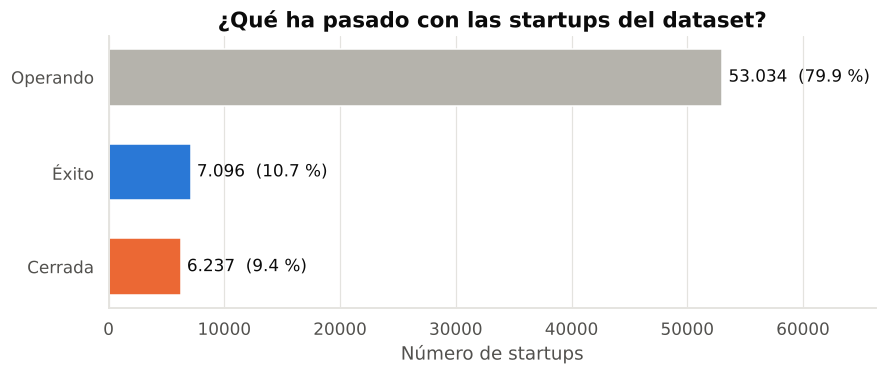

status
operating   79.90
closed       9.40
acquired     8.40
ipo          2.30
Name: proportion, dtype: float64

In [11]:
fig = pl.grafico_resultados(df); pl.guardar(fig, "01_resultados"); plt.show()
df["status"].value_counts(normalize=True).mul(100).round(1)

El **80 %** de las startups siguen operando, un **9,4 %** han cerrado y un **10,7 %** han tenido éxito
(8,4 % adquiridas + 2,3 % IPO). Que el % de cierres parezca tan bajo frente al famoso "9 de cada 10 fracasan"
ya es una pista de que hay un sesgo temporal (lo vemos en la sección 8).

### 7.2 Distribución de la financiación total

In [12]:
st.resumen_estadistico(df["funding_total_usd"]).to_frame("funding_total_usd (USD)")

,funding_total_usd (USD)
n,"53,582.00"
media,"18,478,948.44"
mediana,"2,000,000.00"
moda,"1,000,000.00"
desv_tipica,"188,015,010.37"
min,1.00
Q1,"335,810.25"
Q3,"10,000,000.00"
IQR,"9,664,189.75"
max,"30,079,503,000.00"


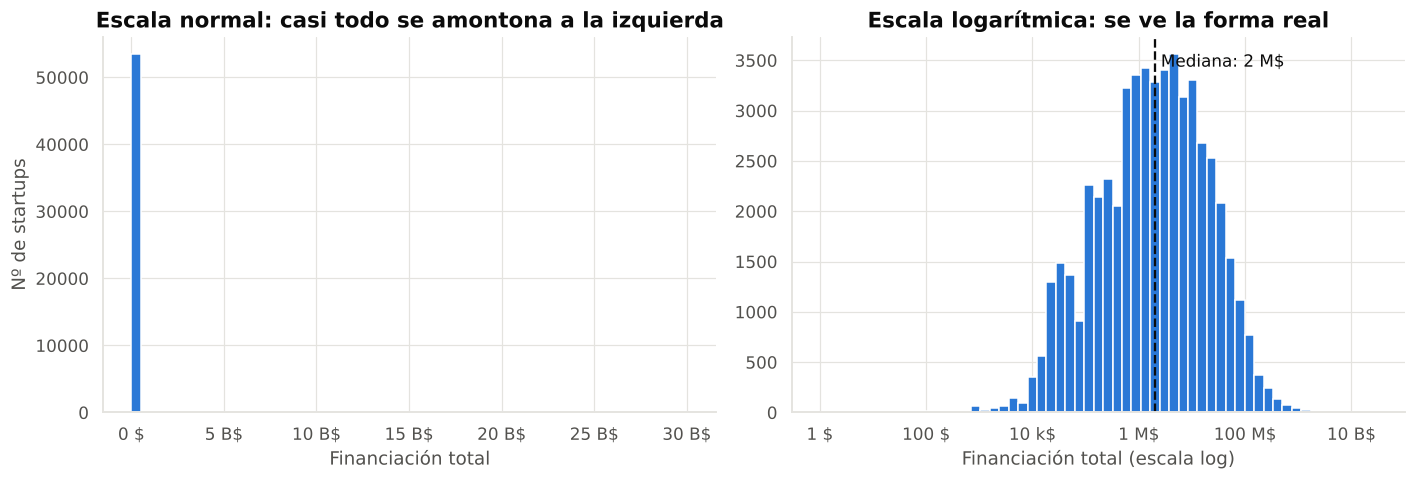

In [13]:
fig = pl.grafico_distribucion_financiacion(df); pl.guardar(fig, "02_distribucion_financiacion"); plt.show()

In [14]:
st.test_normalidad(df["funding_total_usd"]), st.test_normalidad(df["log10_financiacion"])

({'estadistico': np.float64(14510.59),
  'p_valor': np.float64(0.0),
  'es_normal': np.False_},
 {'estadistico': np.float64(60.33),
  'p_valor': np.float64(7.934021934285666e-14),
  'es_normal': np.False_})

**Interpretación:**
- La **media (≈ 18 M$)** es casi **10 veces la mediana (2 M$)**: unas pocas empresas con financiaciones gigantes
  (máximo ≈ 30.000 M$) tiran de la media hacia arriba. La asimetría es enorme.
- Por eso usaremos **medianas** en vez de medias, **escala logarítmica** en los gráficos, y
  **tests no paramétricos** (Mann-Whitney, Kruskal-Wallis, Spearman, chi-cuadrado), que no exigen que los datos sean normales.
- El test de normalidad lo confirma: la variable **no** es normal (p < 0.05), ni siquiera en logaritmo.

### 7.3 Número de rondas, tipo de inversor y geografía

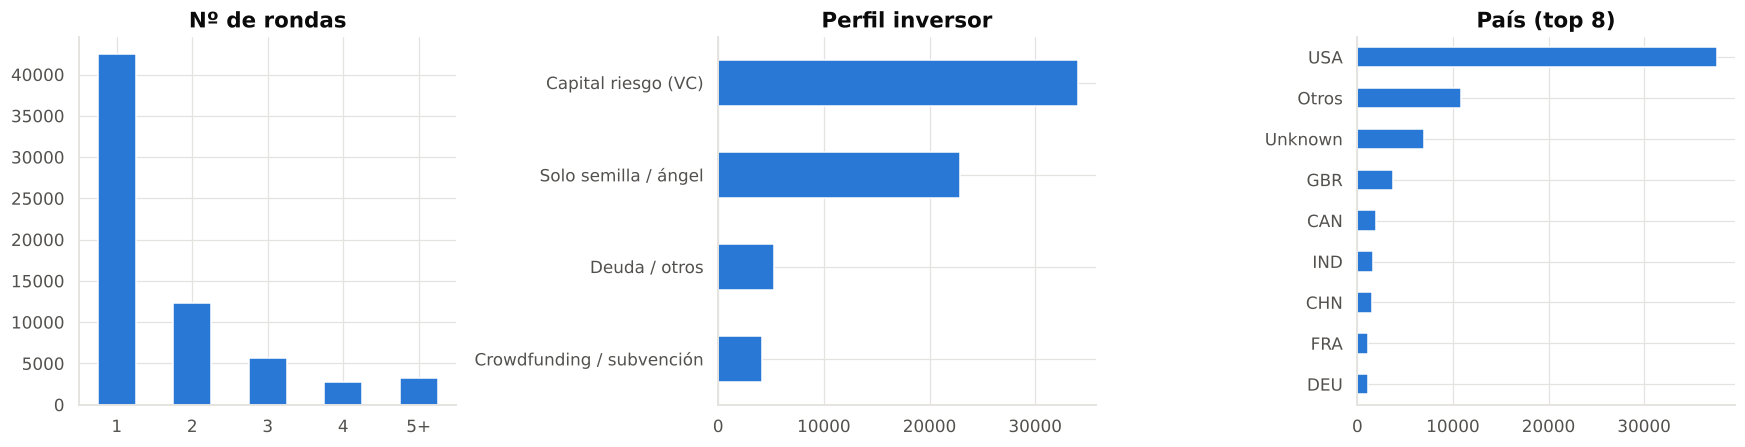

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
df["rondas_grupo"].value_counts().sort_index().plot.bar(ax=axes[0], color=pl.COLORES["Éxito"], rot=0)
axes[0].set_title("Nº de rondas"); axes[0].set_xlabel("")
df["perfil_inversor"].value_counts().sort_values().plot.barh(ax=axes[1], color=pl.COLORES["Éxito"])
axes[1].set_title("Perfil inversor"); axes[1].set_ylabel("")
df["pais_top"].value_counts().sort_values().plot.barh(ax=axes[2], color=pl.COLORES["Éxito"])
axes[2].set_title("País (top 8)"); axes[2].set_ylabel("")
for ax in axes: ax.grid(axis="y" if ax is axes[0] else "x", visible=True)
fig.tight_layout(); pl.guardar(fig, "03_univariante_categoricas"); plt.show()

- La mayoría de startups (**≈ 60 %**) solo tienen **1 ronda**.
- La mitad ha recibido capital riesgo (VC) en algún momento; un tercio solo semilla/ángel.
- **EE. UU. concentra el 57 %** de las startups; España aparece con ~750 (fuera del top 8).

## 8. Un sesgo importante: la edad de la startup

Antes de cruzar financiación y resultados hay que tener en cuenta algo crítico:
**una startup que recibió su primera ronda en 2014 no ha tenido tiempo ni de cerrar ni de venderse** en 2015.
Si mezclamos startups jóvenes y veteranas, el resultado se contamina.

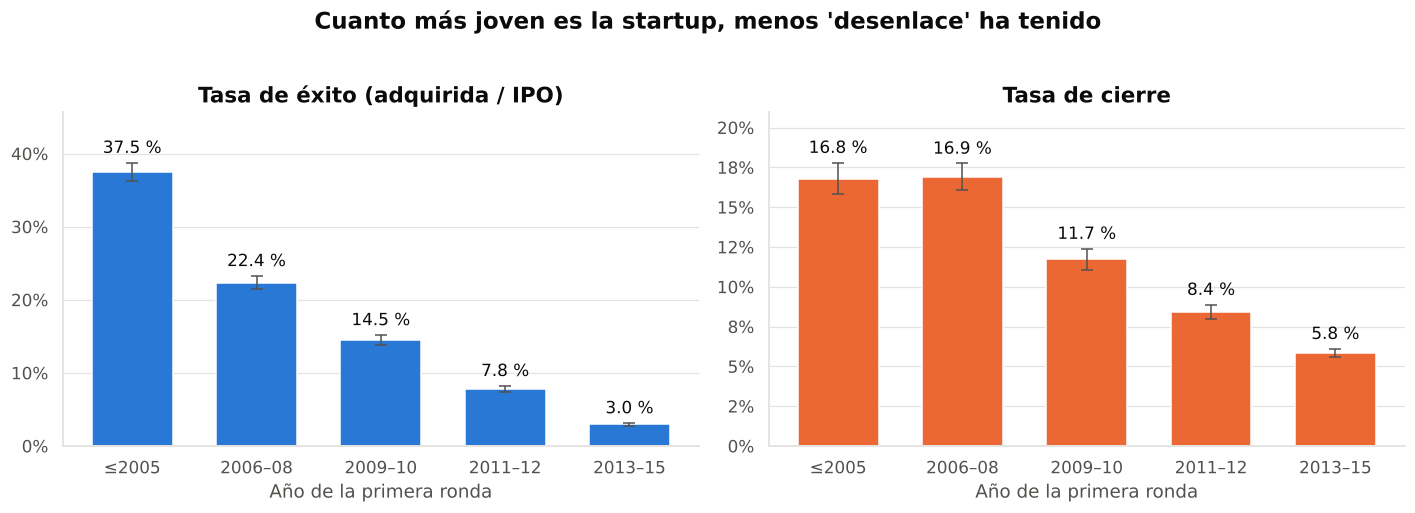

,cohorte,n,tasa_exito,tasa_cerrada
0,≤2005,5475,37.48,16.79
1,2006–08,7938,22.35,16.91
2,2009–10,8992,14.46,11.72
3,2011–12,13873,7.78,8.40
4,2013–15,30062,2.96,5.84


In [16]:
tabla_cohorte = st.tasas_por_grupo(df, "cohorte")
fig = pl.grafico_tasas(tabla_cohorte, "cohorte", "Cuanto más joven es la startup, menos 'desenlace' ha tenido",
                       xlabel="Año de la primera ronda")
pl.guardar(fig, "04_sesgo_cohorte"); plt.show()
tabla_cohorte[["cohorte", "n", "tasa_exito", "tasa_cerrada"]]

Las startups financiadas antes de 2006 tienen un 37 % de éxitos; las de 2013-15, solo un 3 %. No es que las nuevas sean peores:
**simplemente no ha pasado el tiempo suficiente**.

**Decisión:** para las hipótesis H1-H5 trabajo con la **cohorte madura** (primera ronda ≤ 2010, al menos 5 años de recorrido)
y con financiación conocida. Así comparo startups que han tenido tiempo de "decidir" su destino.

In [17]:
maduras = df[df["cohorte_madura"] & df["funding_total_usd"].notna()].copy()
print(f"Startups en la cohorte madura con financiación conocida: {len(maduras):,}")
maduras["resultado"].value_counts(normalize=True).mul(100).round(1)

Startups en la cohorte madura con financiación conocida: 19,382


resultado
Operando   62.30
Éxito      23.60
Cerrada    14.10
Name: proportion, dtype: float64

## 9. H1 y H2 — Financiación total vs. supervivencia y éxito

### 9.1 ¿Cuánto dinero recibieron las que triunfaron y las que cerraron?

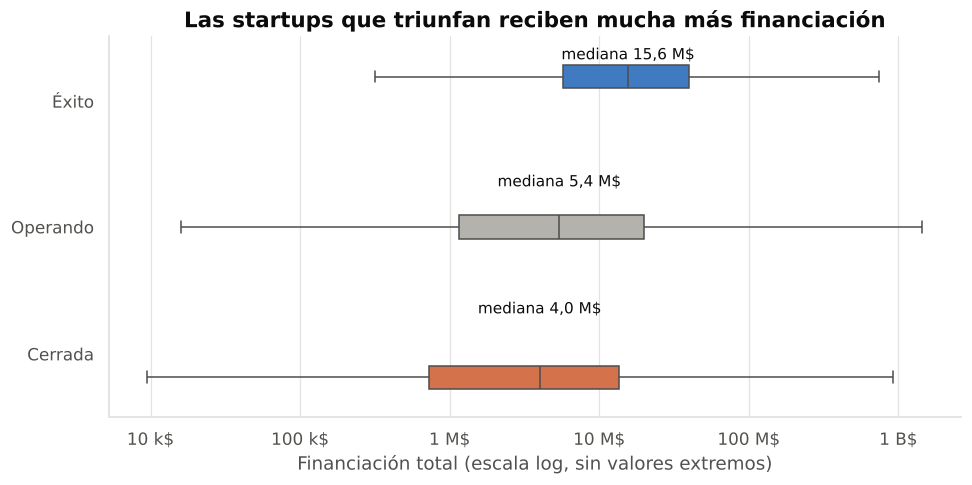

,count,25%,50%,75%
resultado,,,,
Éxito,"4,567.00","5,700,000.00","15,590,000.00","40,000,000.00"
Operando,"12,079.00","1,149,999.50","5,410,000.00","20,000,000.00"
Cerrada,"2,736.00","728,500.00","4,000,000.00","13,470,000.00"


In [18]:
fig = pl.grafico_boxplot_por_resultado(maduras); pl.guardar(fig, "05_boxplot_resultado"); plt.show()
maduras.groupby("resultado", observed=True)["funding_total_usd"].describe()[["count", "25%", "50%", "75%"]]

In [19]:
mw = st.mann_whitney(maduras.loc[maduras.exito == 1, "funding_total_usd"],
                     maduras.loc[maduras.cerrada == 1, "funding_total_usd"], "exito", "cerrada")
kw = st.kruskal_por_grupo(maduras, "funding_total_usd", "resultado")
print("Mann-Whitney (Éxito vs Cerrada):", mw)
print("Kruskal-Wallis (3 grupos):", kw)

Mann-Whitney (Éxito vs Cerrada): {'mediana_exito': np.float64(15590000.0), 'mediana_cerrada': np.float64(4000000.0), 'U': np.float64(9001041.0), 'p_valor': np.float64(8.756650416994352e-219), 'efecto_r': np.float64(0.441), 'significativo': np.True_}
Kruskal-Wallis (3 grupos): {'H': np.float64(1367.43), 'p_valor': np.float64(1.1648172736005349e-297), 'significativo': np.True_}


**Resultado:** la mediana de financiación de las startups con éxito (**≈ 15,6 M$**) es casi **4 veces** la de las que cerraron (**4 M$**).
El test de Mann-Whitney da p < 0.001 y un tamaño de efecto *r* ≈ 0,44 (moderado): si cogemos al azar una startup de éxito y una cerrada,
la de éxito ha recibido más dinero en ~7 de cada 10 casos.

### 9.2 Tasas de éxito y de cierre por tramo de financiación

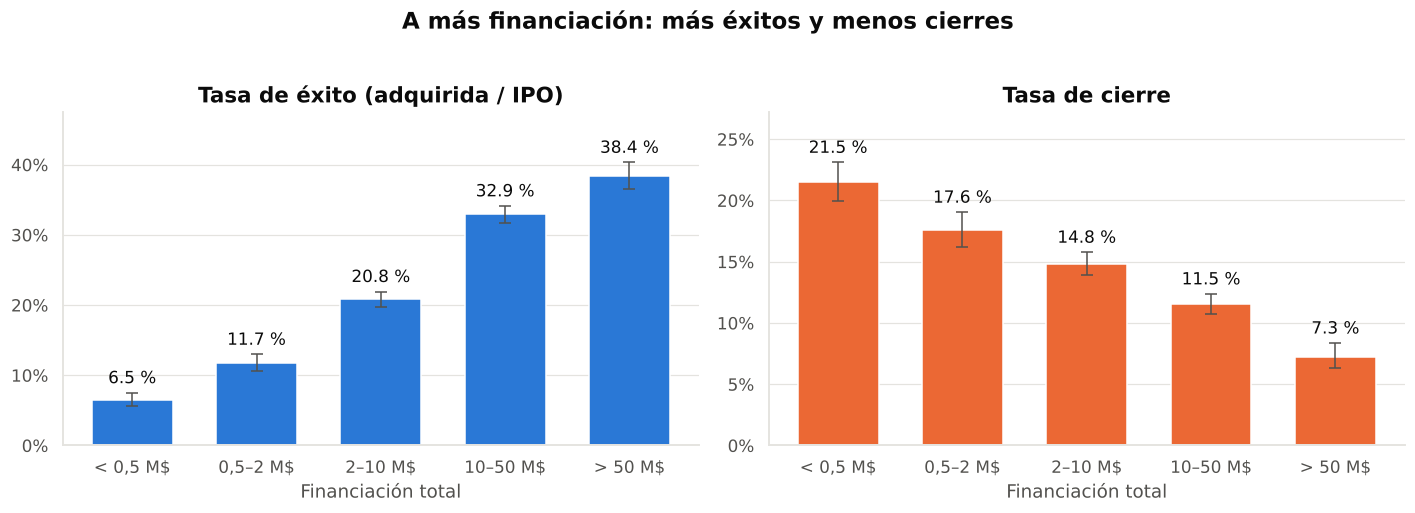

,tramo_financiacion,n,tasa_exito,exito_ic_inf,exito_ic_sup,tasa_cerrada,cerrada_ic_inf,cerrada_ic_sup
0,"< 0,5 M$",2548,6.48,5.58,7.50,21.47,19.92,23.10
1,"0,5–2 M$",2837,11.74,10.60,12.97,17.59,16.23,19.03
2,2–10 M$,5561,20.82,19.78,21.91,14.80,13.89,15.76
3,10–50 M$,5971,32.91,31.73,34.11,11.52,10.74,12.36
4,> 50 M$,2465,38.38,36.48,40.31,7.26,6.30,8.35


In [20]:
tabla_tramo = st.tasas_por_grupo(maduras, "tramo_financiacion")
fig = pl.grafico_tasas(tabla_tramo, "tramo_financiacion",
                       "A más financiación: más éxitos y menos cierres", xlabel="Financiación total")
pl.guardar(fig, "06_tasas_por_tramo"); plt.show()
tabla_tramo

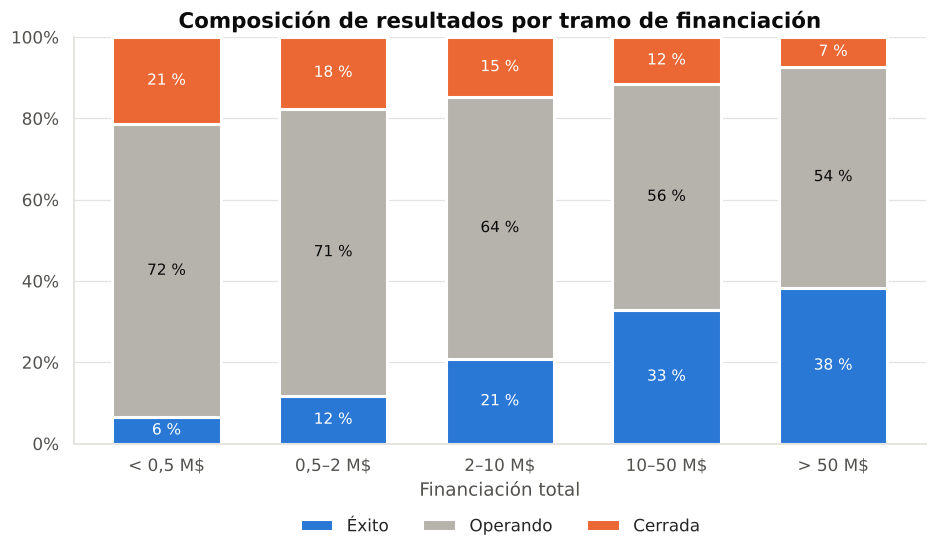

In [21]:
fig = pl.grafico_resultado_apilado(maduras, "tramo_financiacion",
                                   "Composición de resultados por tramo de financiación", "Financiación total")
pl.guardar(fig, "07_apilado_tramo"); plt.show()

In [22]:
print("Chi-cuadrado tramo x resultado:", st.chi_cuadrado(maduras, "tramo_financiacion", "resultado"))
print("Spearman financiación ~ éxito: ", st.spearman(maduras["funding_total_usd"], maduras["exito"]))
print("Spearman financiación ~ cierre:", st.spearman(maduras["funding_total_usd"], maduras["cerrada"]))

Chi-cuadrado tramo x resultado: {'chi2': np.float64(1329.9), 'p_valor': np.float64(8.098267442381605e-282), 'grados_libertad': 8, 'v_cramer': np.float64(0.185), 'n': 19382, 'significativo': np.True_}
Spearman financiación ~ éxito:  {'rho': np.float64(0.257), 'p_valor': np.float64(5.399227967908123e-291), 'n': 19382, 'significativo': np.True_}
Spearman financiación ~ cierre: {'rho': np.float64(-0.122), 'p_valor': np.float64(8.78555992494665e-65), 'n': 19382, 'significativo': np.True_}


**Conclusión H1 y H2: ✅ se cumplen.**

| Tramo | Tasa de éxito | Tasa de cierre |
|---|---|---|
| < 0,5 M$ | 6,5 % | 21,5 % |
| > 50 M$ | 38,4 % | 7,3 % |

- La **tasa de éxito se multiplica por ~6** y la **tasa de cierre se divide por ~3** del primer al último tramo.
- La relación es **estadísticamente significativa** (chi-cuadrado p < 0.001) con un tamaño de efecto *débil* (V de Cramér ≈ 0,19):
  la financiación **importa**, pero **no lo explica todo**.
- El efecto es **más fuerte sobre el éxito** (ρ = +0,26) que sobre la supervivencia (ρ = −0,12).

## 10. H3 — ¿Importa el número de rondas?

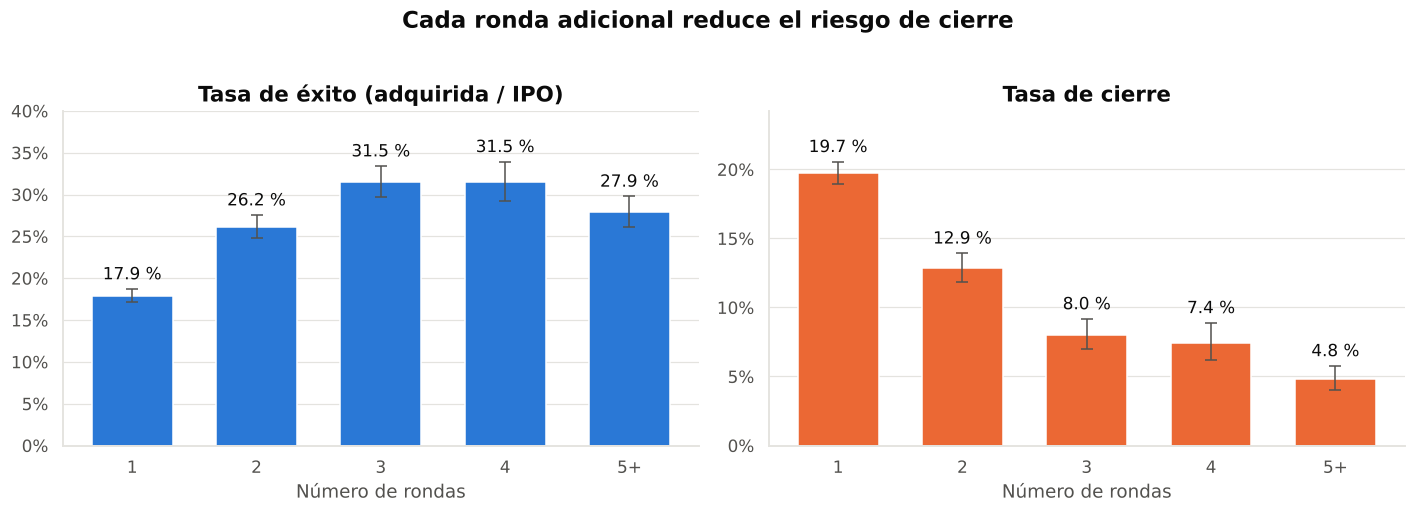

,rondas_grupo,n,tasa_exito,tasa_cerrada
0,1,9102,17.91,19.73
1,2,4096,26.17,12.87
2,3,2396,31.51,8.01
3,4,1467,31.49,7.43
4,5+,2321,27.92,4.83


In [23]:
tabla_rondas = st.tasas_por_grupo(maduras, "rondas_grupo")
fig = pl.grafico_tasas(tabla_rondas, "rondas_grupo", "Cada ronda adicional reduce el riesgo de cierre",
                       xlabel="Número de rondas")
pl.guardar(fig, "08_tasas_por_rondas"); plt.show()
tabla_rondas[["rondas_grupo", "n", "tasa_exito", "tasa_cerrada"]]

Pero, ¿no será que las que tienen más rondas simplemente tienen más dinero? Para separar ambos efectos
miro la **tasa de cierre para cada combinación de tramo de financiación y número de rondas**:

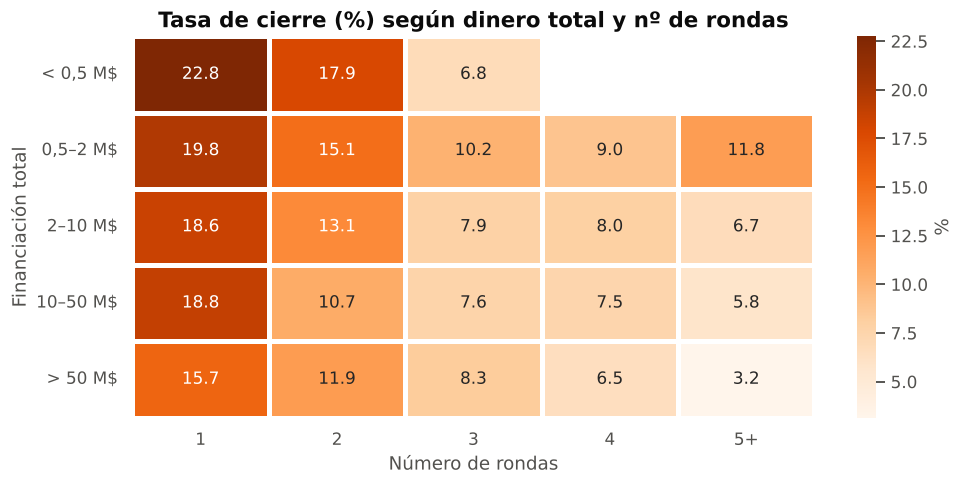

In [24]:
fig = pl.grafico_heatmap(maduras, "tramo_financiacion", "rondas_grupo", "cerrada",
                         "Tasa de cierre (%) según dinero total y nº de rondas",
                         xlabel="Número de rondas", ylabel="Financiación total", cmap="Oranges")
pl.guardar(fig, "09_heatmap_tramo_rondas"); plt.show()

In [25]:
print("Chi-cuadrado rondas x resultado:", st.chi_cuadrado(maduras, "rondas_grupo", "resultado"))
print("Spearman nº rondas ~ cierre:", st.spearman(maduras["funding_rounds"], maduras["cerrada"]))

Chi-cuadrado rondas x resultado: {'chi2': np.float64(728.86), 'p_valor': np.float64(4.3696217073764e-152), 'grados_libertad': 8, 'v_cramer': np.float64(0.137), 'n': 19382, 'significativo': np.True_}
Spearman nº rondas ~ cierre: {'rho': np.float64(-0.166), 'p_valor': np.float64(1.820759034253277e-119), 'n': 19382, 'significativo': np.True_}


Y al revés: ¿protege empezar con una **primera ronda muy grande**?

In [26]:
m_pr = maduras.dropna(subset=["importe_primera_ronda"]).copy()
m_pr["quintil_1a_ronda"] = pd.qcut(m_pr["importe_primera_ronda"], 5,
                                   labels=["Q1 (≤0,5 M$)", "Q2", "Q3", "Q4", "Q5 (>11 M$)"])
st.tasas_por_grupo(m_pr, "quintil_1a_ronda")[["quintil_1a_ronda", "n", "tasa_exito", "tasa_cerrada"]]

,quintil_1a_ronda,n,tasa_exito,tasa_cerrada
0,"Q1 (≤0,5 M$)",4237,10.29,17.70
1,Q2,3527,16.47,13.69
2,Q3,4375,23.73,12.94
3,Q4,3458,32.39,12.35
4,Q5 (>11 M$),3785,36.78,13.47


**Conclusión H3: ✅ se cumple (y es uno de los hallazgos más interesantes).**

- Con **el mismo dinero total**, las startups que lo reciben en **más rondas cierran mucho menos**.
  Ejemplo: en el tramo 2–10 M$, la tasa de cierre pasa del **18,6 %** con 1 ronda al **6,7 %** con 5 o más.
- Interpretación: cada ronda es una **validación externa**: un inversor ha vuelto a revisar la empresa y ha decidido seguir apostando.
  Además, recibir el dinero por etapas obliga a cumplir hitos.
- El número de rondas está algo más relacionado con la supervivencia (ρ = −0,17) que el importe total (ρ = −0,12).
- Una **primera ronda grande no protege del cierre**: la tasa de cierre se queda plana en torno al 12-13 % a partir del segundo quintil.
  Lo que protege es **seguir convenciendo a inversores** ronda tras ronda.

## 11. H4 — ¿Más dinero siempre es mejor? Rendimientos decrecientes

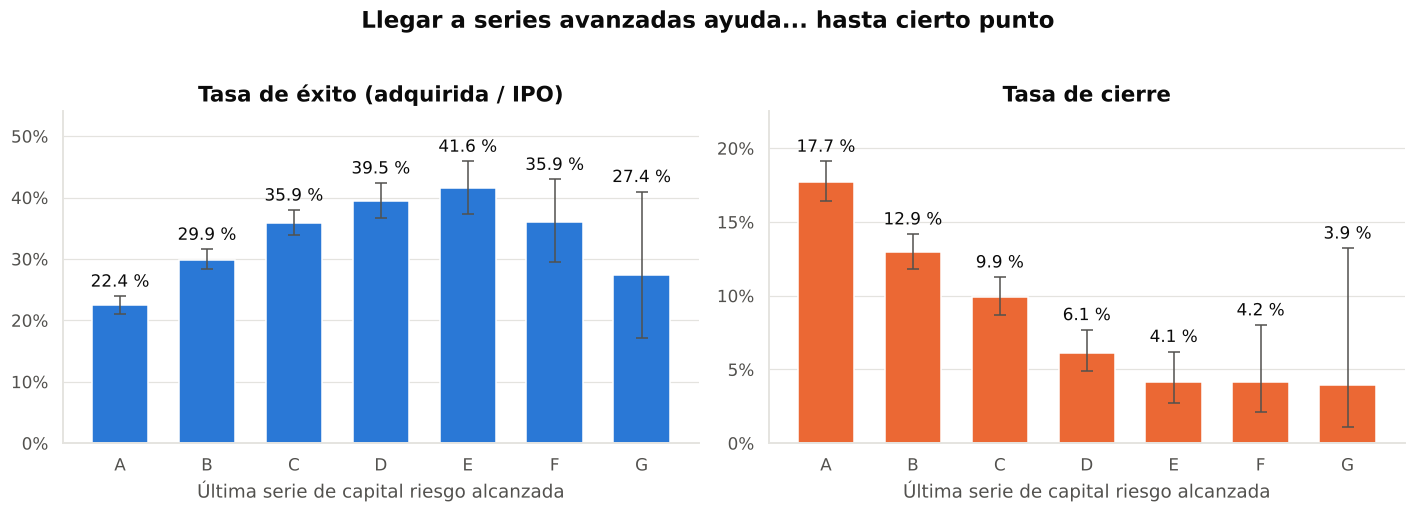

,serie_maxima,n,tasa_exito,tasa_cerrada
0,A,3173,22.44,17.74
1,B,3053,29.91,12.94
2,C,2089,35.85,9.91
3,D,1125,39.47,6.13
4,E,510,41.57,4.12
5,F,192,35.94,4.17
6,G,51,27.45,3.92


In [27]:
tabla_serie = st.tasas_por_grupo(maduras.dropna(subset=["serie_maxima"]), "serie_maxima")
tabla_serie = tabla_serie[tabla_serie["n"] >= 50]   # descartamos series con muy pocas empresas
fig = pl.grafico_tasas(tabla_serie, "serie_maxima", "Llegar a series avanzadas ayuda... hasta cierto punto",
                       xlabel="Última serie de capital riesgo alcanzada")
pl.guardar(fig, "10_tasas_por_serie"); plt.show()
tabla_serie[["serie_maxima", "n", "tasa_exito", "tasa_cerrada"]]

**Conclusión H4: ❌ se refuta parcialmente — sorpresa.**
- La **tasa de cierre sí baja siempre** (de 17,7 % en serie A a ~4 % en series E-G).
- Pero la **tasa de éxito toca techo**: sube hasta la **serie E (≈ 42 %)** y después **baja** (serie G: 27 %).
  Ojo: en las series F y G hay pocas empresas (192 y 51) y sus intervalos de confianza son anchos, así que esa caída es un **indicio**, no una prueba.
- La evidencia más sólida está en el **nº de rondas** (muestras grandes): el éxito se estanca en 3-4 rondas (≈ 31,5 %)
  y **baja con 5 o más (27,9 %)**, y aquí los intervalos de confianza ya no se solapan.
- Interpretación: una empresa que necesita **muchísimas rondas** puede que no encuentre la salida (comprador o bolsa) y siga quemando capital.
  El dinero ayuda a **no morir**, pero a partir de cierto punto **no garantiza una salida**.

## 12. H5 — País y sector

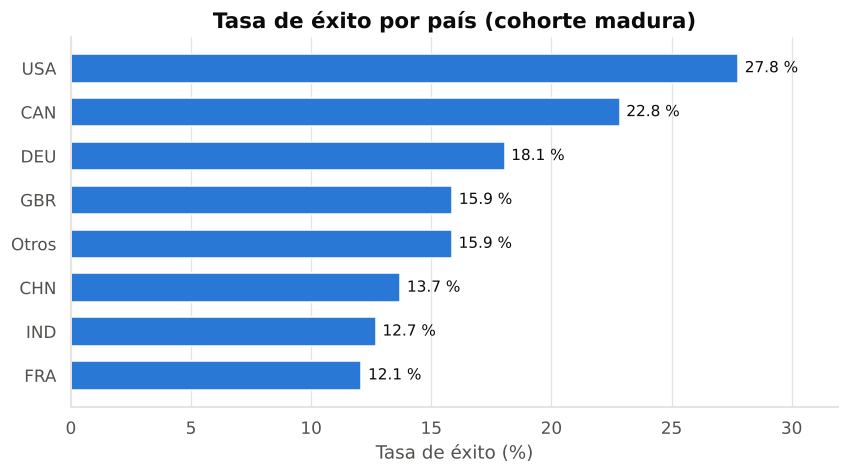

,n,tasa_exito,tasa_cerrada
pais_top,,,
USA,12850,27.77,12.73
CAN,543,22.84,14.92
DEU,277,18.05,11.55
GBR,983,15.87,14.34
Otros,2125,15.86,15.11
CHN,569,13.71,5.98
IND,197,12.69,10.15
FRA,488,12.09,10.66


In [28]:
tabla_pais = st.tasas_por_grupo(maduras[maduras["pais_top"] != "Unknown"], "pais_top").set_index("pais_top")
fig = pl.grafico_barras_h(tabla_pais["tasa_exito"], "Tasa de éxito por país (cohorte madura)", "Tasa de éxito (%)")
pl.guardar(fig, "11_exito_por_pais"); plt.show()
tabla_pais[["n", "tasa_exito", "tasa_cerrada"]].sort_values("tasa_exito", ascending=False)

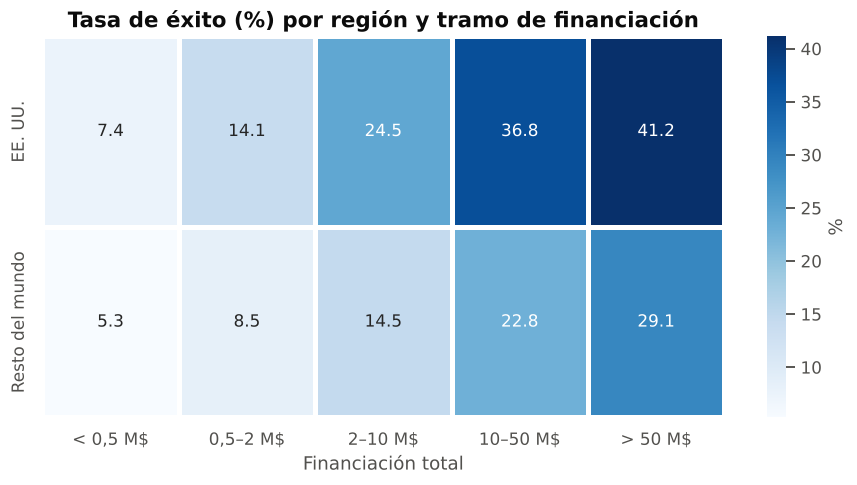

In [29]:
# ¿Se mantiene el efecto de la financiación dentro de EE. UU. y fuera?
maduras["region_simple"] = np.where(maduras["country_code"] == "USA", "EE. UU.", "Resto del mundo")
fig = pl.grafico_heatmap(maduras, "region_simple", "tramo_financiacion", "exito",
                         "Tasa de éxito (%) por región y tramo de financiación",
                         xlabel="Financiación total", ylabel="")
pl.guardar(fig, "12_heatmap_region_tramo"); plt.show()

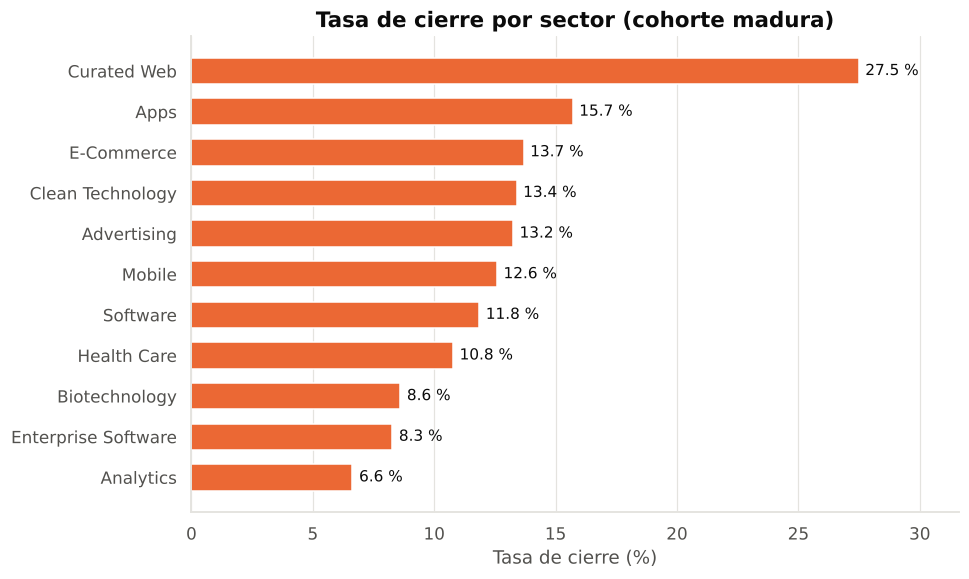

,n,tasa_exito,tasa_cerrada
categoria_top,,,
Analytics,407,29.48,6.63
Enterprise Software,641,34.01,8.27
Biotechnology,2222,25.56,8.60
Health Care,548,25.00,10.77
Software,1891,26.02,11.85
Mobile,612,27.29,12.58
Advertising,891,28.17,13.24
Clean Technology,672,13.84,13.39
E-Commerce,563,19.01,13.68


In [30]:
tabla_cat = st.tasas_por_grupo(maduras[~maduras["categoria_top"].isin(["Unknown", "Otros"])], "categoria_top").set_index("categoria_top")
fig = pl.grafico_barras_h(tabla_cat["tasa_cerrada"], "Tasa de cierre por sector (cohorte madura)",
                          "Tasa de cierre (%)", color=pl.COLORES["Cerrada"])
pl.guardar(fig, "13_cierre_por_sector"); plt.show()
tabla_cat[["n", "tasa_exito", "tasa_cerrada"]].sort_values("tasa_cerrada")

**Conclusión H5: ✅ se cumple.**
- **EE. UU. tiene un 27,8 % de éxito** frente al 12-18 % de Reino Unido, Francia, Alemania o India.
- Pero **el efecto de la financiación se mantiene dentro de cada región**: tanto en EE. UU. como fuera, más dinero = más éxito.
  Es decir, el resultado de H2 **no es solo un efecto "EE. UU."**.
- Por sectores: *Enterprise Software* y *Analytics* son los más sólidos; *Curated Web* (webs de contenido) cierra muchísimo (27 %).
- Nota de calidad de datos: las startups con país o sector **"Unknown"** tienen tasas de cierre altísimas (31 % y 52 %).
  Probablemente las empresas que cierran dejan de actualizar su ficha → la información incompleta es en sí una señal de fracaso.

## 13. Matriz de correlación

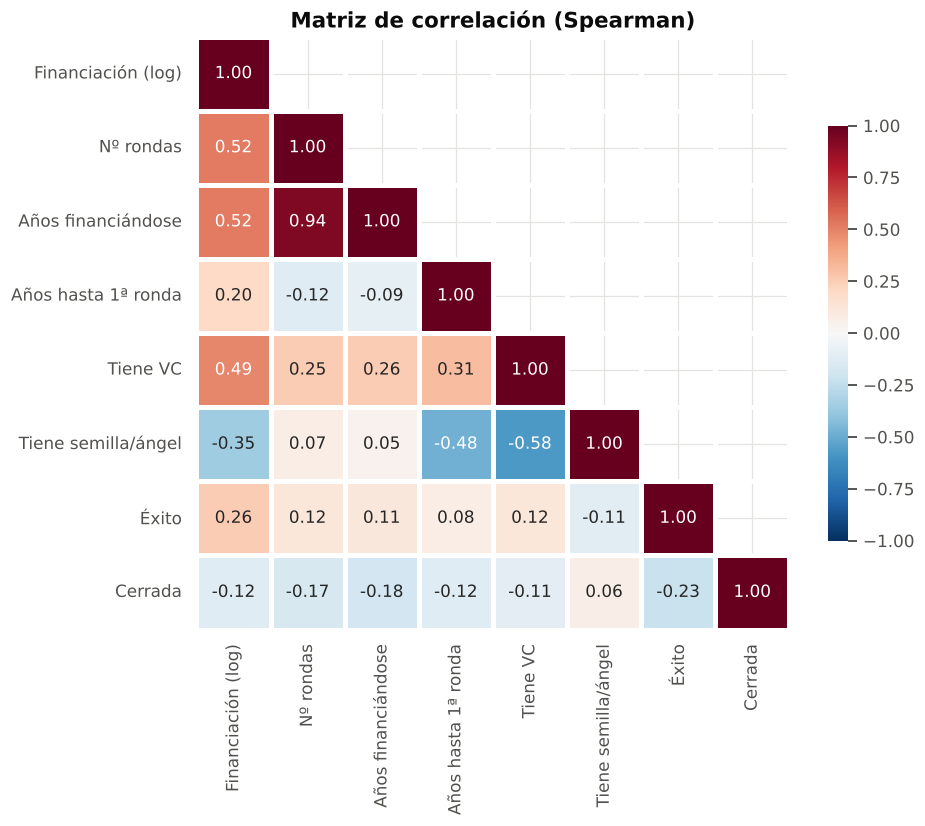

In [31]:
columnas = ["log10_financiacion", "funding_rounds", "años_financiandose", "años_hasta_1a_ronda",
            "tiene_capital_riesgo", "tiene_semilla_angel", "exito", "cerrada"]
nombres = {"log10_financiacion": "Financiación (log)", "funding_rounds": "Nº rondas",
           "años_financiandose": "Años financiándose", "años_hasta_1a_ronda": "Años hasta 1ª ronda",
           "tiene_capital_riesgo": "Tiene VC", "tiene_semilla_angel": "Tiene semilla/ángel",
           "exito": "Éxito", "cerrada": "Cerrada"}
fig = pl.grafico_correlaciones(maduras, columnas, nombres); pl.guardar(fig, "14_correlaciones"); plt.show()

**Cómo leerla:** cada casilla dice cuánto "se mueven juntas" dos variables, de −1 (cuando una sube, la otra baja) a +1 (suben juntas). 0 = no hay relación.

- **Éxito** se relaciona positivamente con financiación (+0,26), tener VC y nº de rondas.
- **Cerrada** se relaciona negativamente con nº de rondas, financiación y años financiándose.
- Ninguna correlación es muy alta (> 0,5): **el éxito de una startup depende de muchos factores**, la financiación es solo uno.

## 14. Resumen de hipótesis

| # | Hipótesis | Resultado | Dato clave |
|---|---|---|---|
| H1 | Más financiación → menos cierres | ✅ Se cumple | Cierre 21,5 % (< 0,5 M$) → 7,3 % (> 50 M$) |
| H2 | Más financiación → más éxitos | ✅ Se cumple (efecto más fuerte) | Éxito 6,5 % → 38,4 % |
| H3 | Más rondas → mejor, incluso con el mismo dinero | ✅ Se cumple | 2–10 M$: cierre 18,6 % (1 ronda) vs 6,7 % (5+) |
| H4 | Más dinero/rondas = siempre mejor | ❌ Parcialmente refutada | El éxito toca techo en serie E (42 %) y luego baja |
| H5 | EE. UU. tiene más éxito | ✅ Se cumple | 27,8 % vs 12–18 %; el efecto de la financiación se mantiene en ambas regiones |

## 15. Conclusiones, limitaciones y próximos pasos

### Conclusiones
1. **Sí, la financiación influye**, y mucho más en el **éxito** (ser vendida o salir a bolsa) que en la mera **supervivencia**.
2. **No solo importa cuánto, sino cómo**: recibir el dinero en **varias rondas** está asociado a menos cierres,
   incluso a igualdad de importe total.
3. **Rendimientos decrecientes**: más allá de la serie E o de 4 rondas, más dinero ya no aumenta la probabilidad de éxito.

### Limitaciones (importante tenerlas presentes)
- **Correlación ≠ causalidad.** Puede que el dinero haga triunfar a las startups... o que las startups buenas atraigan más dinero
  (causalidad inversa). Con estos datos no podemos separar ambas cosas.
- **Sesgo de registro:** Crunchbase recoge mejor a las startups financiadas y de EE. UU.; las que cierran a menudo dejan su ficha incompleta.
- **Datos hasta 2015:** los datos no incluyen la era post-2015 (megarrondas, COVID, IA). Sería interesante repetir el análisis con datos actuales.
- **"Operando" no es lo mismo que éxito:** muchas "operando" pueden ser *zombies* (vivas pero sin crecer).

### Próximos pasos
- Modelo predictivo (regresión logística / árboles) para estimar la probabilidad de éxito controlando por país, sector y año a la vez.
- Análisis de supervivencia (curvas de Kaplan-Meier) usando el tiempo hasta el cierre o la salida.
- Actualizar con datos recientes (Crunchbase API, Dealroom) y centrar el análisis en el ecosistema español.